# Rede de filas de incidentes de TI

Fonte do dataset: https://archive.ics.uci.edu/dataset/498/incident+management+process+enriched+event+log

Esse python notebook contém o tratamento inicial dos dados e execução do modelo base, do modelo melhorado e de cada melhoria separada.
Rode os blocos em ordem.

In [1]:
import json
import os
import re
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CSV = "dataset/incident+management+process+enriched+event+log/incident_event_log.csv"
PERIODO = ("2016-03-01", "2016-06-01")  # meses com operação no log: base para feriados e expediente
JANELA = ("2016-04-01", "2016-06-01")  # período usado no modelo
FILAS = {"Group 70": "N1", "Group 20": "N2a", "Group 39": "N2b"}  # demais grupos = OUTROS
NOMES_FILAS = ["N1", "N2a", "N2b", "OUTROS"]
os.makedirs("resultados", exist_ok=True)
os.makedirs("modelos", exist_ok=True)


def dentro(datas, periodo):
    # True para as datas dentro do período [início, fim)
    return (datas >= periodo[0]) & (datas < periodo[1])


log = pd.read_csv(CSV, na_values="?", low_memory=False)
for coluna in ["opened_at", "sys_updated_at"]:
    log[coluna] = pd.to_datetime(log[coluna], format="%d/%m/%Y %H:%M")
log = log.sort_values(["number", "sys_updated_at", "sys_mod_count"])

## 1. Feriados
- Dias úteis com menos de 30% das aberturas de chamados de um dia útil típico são tratados como feriado. Todos os casos aqui coincidem com feriados de fato, e feriadões (dias ponte).
- Incidentes únicos aparecem em várias linhas (atualizações), para contar incidentes contamos incidentes únicos via o number

In [2]:
incidentes = log.drop_duplicates("number")
abertos = incidentes[dentro(incidentes["opened_at"], PERIODO)]

por_dia = abertos["opened_at"].dt.date.value_counts().sort_index()
dias = pd.DataFrame({"aberturas": por_dia})
dias.index = pd.to_datetime(dias.index)
dias["dia_da_semana"] = dias.index.day_name()

dias_uteis = dias[dias.index.dayofweek < 5].copy()
mediana = dias_uteis["aberturas"].median()
dias_uteis["%_da_mediana"] = (100 * dias_uteis["aberturas"] / mediana).round(1)
dias_uteis["feriado"] = dias_uteis["%_da_mediana"] < 30

# sexta santa, tiradentes, ponte de tiradentes, corpus christi, ponte de corpus christi
FERIADOS = [d.strftime("%Y-%m-%d") for d in dias_uteis[dias_uteis["feriado"]].index]

print(dias_uteis.to_string())

            aberturas dia_da_semana  %_da_mediana  feriado
opened_at                                                 
2016-03-01        315       Tuesday          86.4    False
2016-03-02        465     Wednesday         127.6    False
2016-03-03        392      Thursday         107.5    False
2016-03-04        388        Friday         106.4    False
2016-03-07        607        Monday         166.5    False
2016-03-08        434       Tuesday         119.1    False
2016-03-09        340     Wednesday          93.3    False
2016-03-10        312      Thursday          85.6    False
2016-03-11        329        Friday          90.3    False
2016-03-14        459        Monday         125.9    False
2016-03-15        382       Tuesday         104.8    False
2016-03-16        372     Wednesday         102.1    False
2016-03-17        334      Thursday          91.6    False
2016-03-18        334        Friday          91.6    False
2016-03-21        438        Monday         120.2    Fal

## 2. Horário de expediente
- As atualizações dos chamados mostram quando os atendentes trabalham. Os dados mostram que o range de horário com mais pico é entre 8h e 18h
- Registros para o estado "Closed" ficam de fora, pois parecem ser feitas por uma rotina automática de fechamento de chamado (ocorrem após status "Resolved" 5 dias depois da atualização de status, não devem ser usado então para contabilizar expediente).

In [3]:
atualizacoes = log[dentro(log["sys_updated_at"], PERIODO)]
atualizacoes = atualizacoes[atualizacoes["incident_state"] != "Closed"]

dia = atualizacoes["sys_updated_at"].dt.normalize()
eh_dia_util = (atualizacoes["sys_updated_at"].dt.dayofweek < 5) & ~dia.isin(pd.to_datetime(FERIADOS))
uteis = atualizacoes[eh_dia_util]
hora = uteis["sys_updated_at"].dt.hour
qtd_dias = uteis["sys_updated_at"].dt.normalize().nunique()

horario = pd.DataFrame({
    "atualizacoes_por_dia_util": (hora.value_counts().sort_index() / qtd_dias).round(1),
    "%_das_atualizacoes": (100 * hora.value_counts(normalize=True).sort_index()).round(1),
    "pessoas_distintas_por_dia_util": (uteis.groupby([uteis["sys_updated_at"].dt.normalize(), hora])
                                       ["sys_updated_by"].nunique().groupby(level=1).mean().round(1)),
})
horario.index.name = "hora"
print(horario.to_string())

      atualizacoes_por_dia_util  %_das_atualizacoes  pessoas_distintas_por_dia_util
hora                                                                               
0                          11.1                 0.6                             3.8
1                          13.8                 0.8                             3.8
2                           9.6                 0.6                             3.2
3                           6.2                 0.4                             3.0
4                           5.8                 0.3                             3.0
5                           4.6                 0.3                             2.6
6                           7.9                 0.5                             2.9
7                          21.3                 1.2                             6.0
8                         143.4                 8.3                            28.4
9                         191.3                11.0                         

## 3. Visitas às filas
- "Visita" é a permanência de um incidente em uma fila, da chegada do incidente a uma fila até ele sair para outra fila ou ser resolvido.
- Expediente só conta dias úteis em horário comercial
- Quando não tem grupo de atendimento, assume-se o último (ou o próximo se estava sem grupo na entrada)
- Destino é a próxima visita do incidente (uma reabertura conta como retorno). Sem destino é uma saída.

In [4]:
def minutos_uteis(t):
    dia = t.dt.normalize().values.astype("datetime64[D]")
    dias = np.busday_count("2016-01-01", dia, holidays=FERIADOS)
    minuto = np.clip(t.dt.hour * 60 + t.dt.minute, 480, 1080) - 480
    return dias * 600 + np.where(np.is_busday(dia, holidays=FERIADOS), minuto, 0)


df = log[log.incident_state != "-100"].copy()

grupo = df.groupby("number").assignment_group.ffill()
grupo = grupo.groupby(df.number).bfill()
df["fila"] = grupo.map(FILAS).fillna("OUTROS")

terminal = df.incident_state.isin(["Resolved", "Closed"])
primeira_linha = df.groupby("number").cumcount() == 0
df.loc[terminal & ~primeira_linha, "fila"] = "FIM"
df["fim"] = df.groupby("number").sys_updated_at.shift(-1)  # a linha vale até a próxima do incidente
df.loc[terminal & primeira_linha, "fim"] = df.sys_updated_at  # resolvido já no primeiro registro

nova = df.fila != df.groupby("number").fila.shift()
df["visita"] = nova.cumsum()
v = df.groupby("visita").agg(
    number=("number", "first"),
    fila=("fila", "first"),
    opened_at=("opened_at", "first"),
    t0=("sys_updated_at", "first"),
    t1=("fim", "last"),
)
v["primeira"] = ~v.number.duplicated()
v.loc[v.primeira, "t0"] = v.loc[v.primeira, ["t0", "opened_at"]].min(axis=1)  # chegada = abertura
v = v[v.fila != "FIM"].drop(columns="opened_at")

v["destino"] = v.groupby("number").fila.shift(-1).fillna("SAIDA")
v["u0"], v["u1"] = minutos_uteis(v.t0), minutos_uteis(v.t1)
v["dur"] = v.u1 - v.u0  # permanência na fila, em minutos úteis

v.to_csv("resultados/visitas.csv", index=False)
print(v.fila.value_counts().to_string())

fila
N1        17119
OUTROS    16159
N2a        3133
N2b        1735


### 3.1 Escolha das filas
O log tem 78 grupos de atendimento. Uma fila por grupo deixaria o modelo grande demais e com parâmetros pouco confiáveis nos grupos pequenos. Por isso a rede usa os três grupos que têm um papel claro no fluxo e junta os demais em uma fila só:

- **N1 = Group 70**: a porta de entrada. Recebe 52% das aberturas, tem 40% de todas as visitas e é o último grupo de 45% dos incidentes. É o primeiro nível de atendimento.
- **N2a = Group 20** e **N2b = Group 39**: os dois destinos principais quando o N1 escala um chamado, com cerca de 17% dos escalonamentos do Group 70 cada. O próximo destino, o Group 25, recebe só 7%. Funcionam como segundo nível.
- **OUTROS**: os outros 75 grupos, nenhum com mais de 4,3% das visitas. Juntos são cerca de metade das visitas, então não dá para descartá-los, mas nenhum tem volume para virar uma fila própria. O Group 25 tem mais visitas que o Group 39, mas a maioria vem de aberturas diretas e não de escalonamentos do N1, por isso ficou em OUTROS.

Como OUTROS junta grupos muito diferentes, os seus servidores e o seu tempo de atendimento são uma média desses grupos e não descrevem uma equipe real. Esse é um limite do modelo.

A tabela abaixo usa o log inteiro e mostra os números que justificam a escolha.

In [5]:
# cada troca de grupo dentro de um incidente conta como uma visita ao novo grupo
g = df.assign(grupo=grupo)
g = g[g.grupo != g.groupby("number").grupo.shift()].copy()
g["anterior"] = g.groupby("number").grupo.shift()

grupos = pd.DataFrame({
    "%_das_visitas": g.grupo.value_counts(normalize=True),
    "%_das_aberturas": g[g.anterior.isna()].grupo.value_counts(normalize=True),
    "%_dos_escalonamentos_do_N1": g[g.anterior == "Group 70"].grupo.value_counts(normalize=True),
    "%_ultimo_grupo_do_incidente": g.groupby("number").grupo.last().value_counts(normalize=True),
}).fillna(0).mul(100).round(1).sort_values("%_das_visitas", ascending=False)
grupos.insert(0, "fila", grupos.index.map(FILAS).fillna("OUTROS"))

print(f"{len(grupos)} grupos de atendimento; os 8 com mais visitas:")
print(grupos.head(8).to_string())

78 grupos de atendimento; os 8 com mais visitas:
            fila  %_das_visitas  %_das_aberturas  %_dos_escalonamentos_do_N1  %_ultimo_grupo_do_incidente
grupo                                                                                                    
Group 70      N1           39.7             52.5                         0.0                         45.0
Group 20     N2a            7.2              5.7                        16.8                          1.8
Group 25  OUTROS            4.3              3.2                         7.3                          5.2
Group 39     N2b            3.9              1.6                        16.9                          4.9
Group 24  OUTROS            3.5              2.9                         4.5                          4.3
Group 23  OUTROS            2.3              1.2                         3.8                          3.3
Group 73  OUTROS            2.1              2.0                         2.0                          2

## 4. Parâmetros das filas
Chegadas, atendimento, servidores e roteamento de cada fila em abril e maio de 2016.

- Servidores se considerou como número máximo de incidentes que a fila manteve aberto ao mesmo tempo na janela de tempo.

In [6]:
janela = v[dentro(v.t0, JANELA)]  # visitas iniciadas na janela
inicio_util, fim_util = minutos_uteis(pd.Series(pd.to_datetime(JANELA)))
T = fim_util - inicio_util  # minutos úteis da janela
amostras = np.arange(inicio_util, fim_util, 10)  # a cada 10 minutos úteis

par = {}
for f in NOMES_FILAS:
    s = janela[janela.fila == f]
    chegada = T / s.primeira.sum()  # intervalo médio entre chegadas externas (min)
    atendimento = s.dur.mean()  # tempo médio de atendimento = permanência (min)
    todas = v[v.fila == f]
    abertos = np.searchsorted(np.sort(todas.u0), amostras, "right") - np.searchsorted(np.sort(todas.u1), amostras,
                                                                                      "right")
    servidores = int(abertos.max())
    rot = s.destino.value_counts(normalize=True)
    par[f] = {
        "chegada": [0, round(float(2 * chegada), 2)],  # uniforme com a média observada
        "atendimento": [0, round(float(2 * atendimento), 2)],  # uniforme com a média observada
        "servidores": servidores,
        "mu_por_hora": round(float(60 / atendimento), 4),
        "rho": round(float(len(s) / T * atendimento / servidores), 3),  # lambda * S / C (precisa ser < 1)
        "roteamento": {d: round(float(rot.get(d, 0)), 4) for d in NOMES_FILAS},  # o resto vai para a saída
    }
    print(f, par[f])

json.dump(par, open("resultados/parametros.json", "w"), indent=2)

N1 {'chegada': [0, 5.67], 'atendimento': [0, 493.25], 'servidores': 358, 'mu_por_hora': 0.2433, 'rho': 0.318, 'roteamento': {'N1': 0.0067, 'N2a': 0.0485, 'N2b': 0.0653, 'OUTROS': 0.1936}}
N2a {'chegada': [0, 48.2], 'atendimento': [0, 2721.23], 'servidores': 151, 'mu_por_hora': 0.0441, 'rho': 0.741, 'roteamento': {'N1': 0.3371, 'N2a': 0.0, 'N2b': 0.001, 'OUTROS': 0.4852}}
N2b {'chegada': [0, 199.15], 'atendimento': [0, 1220.13], 'servidores': 88, 'mu_por_hora': 0.0984, 'rho': 0.338, 'roteamento': {'N1': 0.2743, 'N2a': 0.0009, 'N2b': 0.0184, 'OUTROS': 0.0386}}
OUTROS {'chegada': [0, 7.83], 'atendimento': [0, 6179.97], 'servidores': 1212, 'mu_por_hora': 0.0194, 'rho': 0.996, 'roteamento': {'N1': 0.1649, 'N2a': 0.0456, 'N2b': 0.0176, 'OUTROS': 0.008}}


## 5. Modelo do simulador
Escreve `modelos/base.yml` com os parâmetros acima.

In [7]:
linhas = ["# Rede de incidentes de TI (abr-mai/2016). Tempo em minutos úteis (8h-18h, dias úteis).",
          "# Gerado pelo notebook a partir de resultados/parametros.json",
          "simulation:", "  max_randoms: 1000000", "  seed: 42", "", "queues:"]
for fila, p in par.items():
    linhas += [f"  {fila}:                 # G/G/{p['servidores']} (capacidade infinita)",
               f"    servers: {p['servidores']}",
               f"    arrival: [{p['chegada'][0]}, {p['chegada'][1]}]",
               f"    service: [{p['atendimento'][0]}, {p['atendimento'][1]}]",
               "    routing:"]
    linhas += [f"      {d}: {prob}" for d, prob in p["roteamento"].items() if prob > 0]
    linhas += ["      # o restante vai para o exterior (incidente resolvido)", ""]

open("modelos/base.yml", "w").write("\n".join(linhas))

1267

## 6. Simulação e índices do M9
Roda o simulador (cerca de 1 minuto) e calcula N, D, U e W de cada fila. Para o modelo melhorado: `indices("modelos/melhorado.yml")`.

In [8]:
def indices(yml):
    nome = yml.split("/")[-1].removesuffix(".yml")
    saida = subprocess.run([sys.executable, "simulator.py", yml], capture_output=True, text=True, check=True).stdout
    open(f"resultados/{nome}_saida.txt", "w").write(saida)

    linhas = []
    # cada fila: cabeçalho "== N1 (G/G/C/infinite) ==", linha "Service interval: [a, b]", perdas e tabela de estados
    for fila, C, corpo in re.findall(r"=+ (\S+) \(G/G/(\d+)/\w+\) =+\n(.*?)(?=\n=+ |\nTotal clients lost \(all)", saida,
                                     re.S):
        C = int(C)
        a, b = map(float, re.search(r"Service interval: \[([\d.]+), ([\d.]+)\]", corpo).groups())
        mu = 1 / ((a + b) / 2)  # taxa de atendimento por servidor (por minuto útil)
        perdas = int(re.search(r"Total clients lost: (\d+)", corpo).group(1))
        estados = [(int(i), float(p)) for i, p in re.findall(r"^\s+(\d+)\*?\s+[\d.]+\s+([\d.]+)", corpo, re.M)]
        N = sum(p * i for i, p in estados)  # população
        D = sum(p * min(i, C) * mu for i, p in estados)  # vazão (por minuto útil)
        U = sum(p * min(i, C) / C for i, p in estados)  # utilização
        linhas.append({"fila": fila, "servidores": C, "K (maior estado)": max(i for i, _ in estados),
                       "perdas": perdas, "N": N, "D (por hora)": 60 * D, "U": U, "W (min)": N / D,
                       "P(todos ocupados)": sum(p for i, p in estados if i >= C)})

    tabela = pd.DataFrame(linhas).set_index("fila")
    tabela.to_csv(f"resultados/{nome}_indices.csv")
    return tabela.round(3)


indices("modelos/base.yml")

,servidores,K (maior estado),perdas,N,D (por hora),U,W (min),P(todos ocupados)
fila,,,,,,,,
N1,358,146,0,113.049,27.503,0.316,246.625,0.00
N2a,151,137,0,109.358,4.822,0.724,1360.615,0.00
N2b,88,51,0,29.058,2.858,0.330,610.065,0.00
OUTROS,1212,1438,0,1225.595,23.161,0.984,3174.953,0.55


### 6.1 Distribuição de probabilidades
Para cada fila, o simulador informa a probabilidade P(i) de a fila ter i chamados (em atendimento ou esperando). Os gráficos mostram essas distribuições. A linha tracejada marca o número de servidores C: à esquerda dela todos os chamados estão em atendimento, e à direita há chamados esperando. A tabela resume cada distribuição. `distribuicao("base", "melhorado")` sobrepõe os dois modelos.

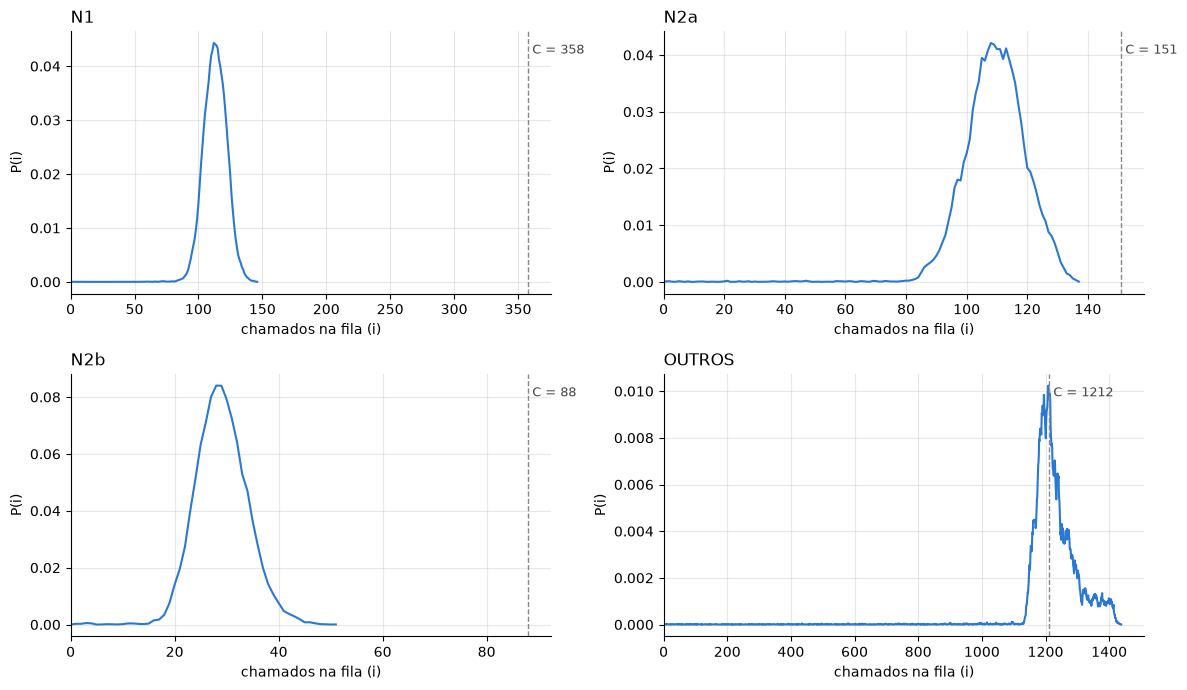

,,servidores,P(0),moda,N (média),faixa de 90%,maior estado,P(i >= C),P(i > C)
fila,modelo,,,,,,,,
N1,base,358,0.0,112,113.049,99 a 127,146,0.00,0.00
N2a,base,151,0.0,108,109.358,94 a 125,137,0.00,0.00
N2b,base,88,0.0,28,29.058,21 a 37,51,0.00,0.00
OUTROS,base,1212,0.0,1209,1225.595,1156 a 1366,1438,0.55,0.54


In [9]:
CORES = ["#2a78d6", "#eb6834"]  # uma cor por modelo, na ordem em que são passados


def distribuicao(*nomes):
    # lê a tabela de estados que indices() salvou em resultados/<nome>_saida.txt
    dist = {}
    for nome in nomes:
        saida = open(f"resultados/{nome}_saida.txt").read()
        for fila, C, corpo in re.findall(r"=+ (\S+) \(G/G/(\d+)/\w+\) =+\n(.*?)(?=\n=+ |\nTotal clients lost \(all)",
                                         saida, re.S):
            estados = re.findall(r"^\s+(\d+)\*?\s+[\d.]+\s+([\d.]+)", corpo, re.M)
            dist[nome, fila] = int(C), pd.Series({int(i): float(p) for i, p in estados})

    resumo = []
    fig, eixos = plt.subplots(2, 2, figsize=(12, 7))
    for eixo, fila in zip(eixos.flat, NOMES_FILAS):
        for nome, cor in zip(nomes, CORES):
            C, p = dist[nome, fila]
            acum = p.cumsum()
            quantil = lambda q: p.index[min(acum.searchsorted(q), len(p) - 1)]
            resumo.append({"fila": fila, "modelo": nome, "servidores": C, "P(0)": p.get(0, 0.0),
                           "moda": p.idxmax(), "N (média)": (p.index * p).sum(),
                           "faixa de 90%": f"{quantil(0.05)} a {quantil(0.95)}", "maior estado": p.index.max(),
                           "P(i >= C)": p[p.index >= C].sum(), "P(i > C)": p[p.index > C].sum()})
            eixo.plot(p.index, p.values, color=cor, lw=1.5, label=nome)
        # C com a cor de cada modelo; se todos têm o mesmo C, uma linha cinza só
        Cs = [dist[nome, fila][0] for nome in nomes]
        unico = len(set(Cs)) == 1
        for k, (C, cor) in enumerate(zip(Cs[:1] if unico else Cs, CORES)):
            eixo.axvline(C, color="#888" if unico else cor, ls="--", lw=1)
            eixo.text(C, 0.95 - 0.08 * k, f" C = {C}", transform=eixo.get_xaxis_transform(), color="#444",
                      fontsize=9, va="top")
        eixo.set_title(fila, loc="left")
        eixo.set_xlabel("chamados na fila (i)")
        eixo.set_ylabel("P(i)")
        eixo.set_xlim(left=0)
        eixo.grid(alpha=0.3)
        eixo.spines[["top", "right"]].set_visible(False)
        if len(nomes) > 1:
            eixo.legend(frameon=False)
    fig.tight_layout()
    plt.show()
    return pd.DataFrame(resumo).set_index(["fila", "modelo"]).round(3)


distribuicao("base")

**Leitura das distribuições do modelo base**
- **N1, N2a e N2b** têm distribuições estreitas e ficam bem à esquerda de C, então nenhuma delas forma fila. O N1 nunca passou de 146 chamados com 358 servidores, e o N2b nunca passou de 51 com 88. O N2a é o que chega mais perto (no máximo 137 de 151 servidores), mas P(i ≥ C) continua 0: nenhum chamado espera.
- **OUTROS** é a única fila que passa de C. A distribuição fica em cima da linha (mediana de cerca de 1217 com C = 1212) e vai até 1438. Em 55% do tempo todos os servidores estão ocupados, e nesses momentos chega a haver até 226 chamados esperando. É o gargalo da rede.
- P(0) = 0 em todas as filas, ou seja, nenhuma fica vazia. O atendimento leva de horas a dias, muito mais que o intervalo entre chegadas, então sempre há chamados abertos.

### 6.2 Perdas
Todas as filas têm capacidade infinita (o campo `capacity` não aparece no yml), então nenhum chamado é perdido. A coluna `perdas` da tabela de índices é 0 em todas as filas, e o total do simulador também é 0 (abaixo).

Isso é intencional e corresponde ao sistema real: um service desk não recusa incidentes. Quando a equipe está sobrecarregada, o chamado fica no backlog esperando atendimento. Por isso, ao contrário do exemplo do M9, em que a lotação aparecia como pacientes perdidos, aqui a saturação aparece como **espera**: estados acima de C na distribuição, P(todos ocupados) e aumento de W. São esses indicadores, e não as perdas, que usamos para comparar o modelo base com o melhorado.

In [10]:
re.search(r"Total clients lost \(all queues\): \d+", open("resultados/base_saida.txt").read()).group()

'Total clients lost (all queues): 0'

## 7. Melhoria Sugerida

**Gargalos identificados no modelo base**
- **OUTROS** é o gargalo principal: utilização de 0,984, todos os servidores ocupados em 55% do tempo, e é a única fila com espera (cerca de 85 minutos úteis). Recebe 19,4% do que sai do N1 e 48,5% do que sai do N2a.
- **N2a** é o ponto de atenção seguinte (utilização de 0,724). N1 e N2b estão folgados (utilização de cerca de 0,32), com capacidade de sobra.

**Alterações em `modelos/melhorado.yml`**
1. **Triagem melhor no N1:** `N1.routing.OUTROS` de 0,1936 para 0,10. Com base de conhecimento e scripts de resolução, parte dos chamados que hoje sobem para OUTROS passa a ser resolvida no próprio N1; essa diferença vai para a saída. O N1 tem folga para absorver isso.
2. **Mais capacidade no gargalo:** `OUTROS.servers` de 1212 para 1300 (+88 vagas de atendimento simultâneo, cerca de 7%).

**Efeito esperado** (equações de tráfego, antes de simular): a chegada total em OUTROS cai de 23,35 para 20,61 por hora, e o `rho` de OUTROS cai de 0,992 para 0,817. Sozinhas, a triagem levaria o `rho` de OUTROS a 0,876 e a capacidade extra a 0,925 (a seção 7.1 testa cada uma separadamente); juntas, atacam a causa (menos carga) e o gargalo (mais capacidade). N1, N2a e N2b também ficam um pouco menos carregadas (N2a: de 0,736 para 0,713), porque menos chamados retornam de OUTROS.

Rode o código abaixo para simular o modelo melhorado e comparar com a tabela da seção 6.

In [11]:
indices("modelos/melhorado.yml")

,servidores,K (maior estado),perdas,N,D (por hora),U,W (min),P(todos ocupados)
fila,,,,,,,,
N1,358,150,0,110.851,26.968,0.310,246.625,0
N2a,151,139,0,106.598,4.701,0.706,1360.615,0
N2b,88,50,0,28.570,2.810,0.325,610.065,0
OUTROS,1300,1157,0,1054.066,20.467,0.811,3089.985,0


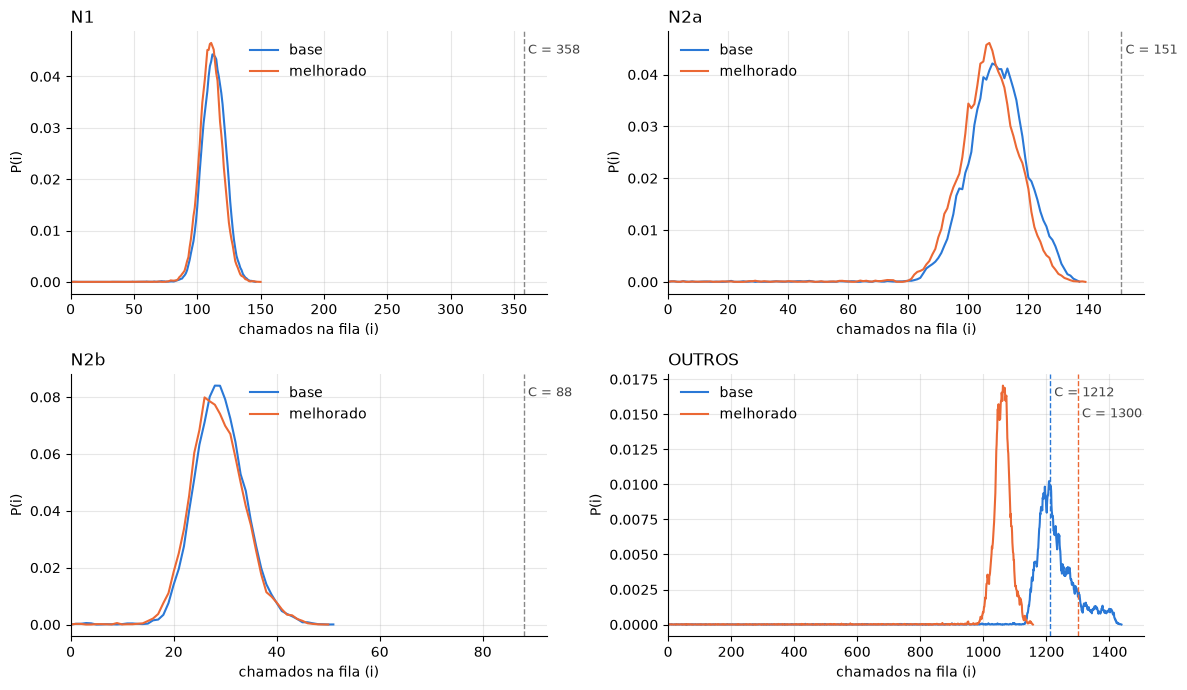

servidores  P(0)  moda  N (média) faixa de 90%  \
fila   modelo                                                      
N1     base              358   0.0   112    113.049     99 a 127   
       melhorado         358   0.0   111    110.851     97 a 125   
N2a    base              151   0.0   108    109.358     94 a 125   
       melhorado         151   0.0   107    106.598     91 a 122   
N2b    base               88   0.0    28     29.058      21 a 37   
       melhorado          88   0.0    26     28.570      21 a 37   
OUTROS base             1212   0.0  1209   1225.595  1156 a 1366   
       melhorado        1300   0.0  1062   1054.066  1014 a 1102   

                  maior estado  P(i >= C)  P(i > C)  
fila   modelo                                        
N1     base                146       0.00      0.00  
       melhorado           150       0.00      0.00  
N2a    base                137       0.00      0.00  
       melhorado           139       0.00      0.00  
N2b    base                 51       0.00      0.00  
       melhorado            50       0.00      0.00  
OUTROS base               1438       0.55      0.54  
       melhorado          1157       0.00      0.00

In [12]:
distribuicao("base", "melhorado")

**Por que o gargalo foi resolvido**

- **Menos carga em OUTROS:** com a triagem melhor, o N1 deixa de escalar parte dos chamados, e a vazão de OUTROS cai de 23,2 para 20,5 chamados por hora. Cada chamado ocupa um servidor de OUTROS por cerca de 3090 min, então menos chegadas significa muito menos servidores ocupados ao mesmo tempo.
- **Mais servidores:** OUTROS passa de 1212 para 1300.
- **Efeito na distribuição:** no modelo base, a distribuição de OUTROS ficava em cima de C. Em 90% do tempo havia entre 1156 e 1366 chamados, e em 55% do tempo todos os servidores estavam ocupados. No modelo melhorado, a distribuição vai para a esquerda e fica inteira abaixo de C: 90% do tempo entre 1014 e 1102 chamados, com no máximo 1157, sem nunca chegar a 1300. P(todos ocupados) cai de 0,55 para 0, a espera cai de cerca de 85 min para 0 e U cai de 0,984 para 0,811.
- **Demais filas:** N1, N2a e N2b não foram alteradas, mas recebem um pouco menos de chamados, porque menos chamados passam por OUTROS e voltam de lá. N e D caem levemente (N2a: N de 109,4 para 106,6). W não muda porque essas filas já não tinham espera, então W é só o tempo de atendimento. A queda de D não é perda de capacidade: é o chamado circulando menos entre as filas, que é o efeito desejado.

### 7.1 Efeito de cada alteração separada
O `melhorado.yml` aplica as duas alterações juntas, então não dá para saber quanto do ganho vem de cada uma. Para separar, geramos dois modelos a partir do `base.yml`, cada um com só uma das alterações:
- `modelos/melhoria_roteamento.yml`: só a triagem melhor no N1 (`N1.routing.OUTROS` de 0,1936 para 0,10);
- `modelos/melhoria_capacidade.yml`: só a capacidade extra em OUTROS (de 1212 para 1300 servidores).

Os quatro cenários (base, cada alteração sozinha e as duas juntas) usam a mesma semente, então as diferenças vêm só das alterações.

In [13]:
# cada alteração do melhorado.yml aplicada sozinha sobre o base.yml
base = open("modelos/base.yml").read()
alteracoes = {
    "melhoria_roteamento": ("só a triagem melhor no N1", [
        ("      OUTROS: 0.1936", "      OUTROS: 0.10    # MELHORIA: era 0.1936"),
    ]),
    "melhoria_capacidade": ("só a capacidade extra em OUTROS", [
        ("# G/G/1212", "# G/G/1300"),
        ("    servers: 1212", "    servers: 1300     # MELHORIA: era 1212"),
    ]),
}
for nome, (descricao, trocas) in alteracoes.items():
    texto = base.replace("# Gerado pelo notebook a partir de resultados/parametros.json",
                         f"# Gerado pelo notebook: base.yml com {descricao}")
    for antes, depois in trocas:
        assert texto.count(antes) == 1, antes
        texto = texto.replace(antes, depois)
    open(f"modelos/{nome}.yml", "w").write(texto)

In [14]:
indices("modelos/melhoria_roteamento.yml")

,servidores,K (maior estado),perdas,N,D (por hora),U,W (min),P(todos ocupados)
fila,,,,,,,,
N1,358,150,0,110.851,26.968,0.310,246.625,0
N2a,151,139,0,106.598,4.701,0.706,1360.615,0
N2b,88,50,0,28.570,2.810,0.325,610.065,0
OUTROS,1212,1157,0,1054.066,20.467,0.870,3089.985,0


In [15]:
indices("modelos/melhoria_capacidade.yml")

,servidores,K (maior estado),perdas,N,D (por hora),U,W (min),P(todos ocupados)
fila,,,,,,,,
N1,358,147,0,113.188,27.537,0.316,246.625,0
N2a,151,146,0,110.729,4.883,0.733,1360.615,0
N2b,88,51,0,28.957,2.848,0.329,610.065,0
OUTROS,1300,1297,0,1195.508,23.214,0.920,3089.985,0


**Comparação dos quatro cenários**

A tabela junta o que muda em OUTROS e o efeito na rede inteira. A espera em OUTROS é W menos o tempo médio de atendimento. O tempo por chamado na rede vem da lei de Little: a população de todas as filas dividida pela taxa de chamados novos. Esse é o tempo que um incidente leva, em média, da abertura até sair da rede.

In [16]:
cenarios = ["base", "melhoria_roteamento", "melhoria_capacidade", "melhorado"]
chegadas_externas = sum(2 / p["chegada"][1] for p in par.values())  # chamados novos por minuto útil
atendimento_outros = par["OUTROS"]["atendimento"][1] / 2  # tempo médio de atendimento em OUTROS (min)

comparacao = []
for nome in cenarios:
    t = pd.read_csv(f"resultados/{nome}_indices.csv", index_col="fila")
    outros = t.loc["OUTROS"]
    comparacao.append({
        "cenário": nome,
        "OUTROS: servidores": outros["servidores"],
        "OUTROS: U": outros["U"],
        "OUTROS: P(todos ocupados)": outros["P(todos ocupados)"],
        "OUTROS: espera (min)": max(outros["W (min)"] - atendimento_outros, 0),
        "N da rede": t["N"].sum(),
        "tempo por chamado na rede (min)": t["N"].sum() / chegadas_externas,
    })
pd.DataFrame(comparacao).set_index("cenário").round(3)

,OUTROS: servidores,OUTROS: U,OUTROS: P(todos ocupados),OUTROS: espera (min),N da rede,tempo por chamado na rede (min)
cenário,,,,,,
base,1212.0,0.984,0.55,84.968,1477.061,2238.996
melhoria_roteamento,1212.0,0.870,0.00,0.000,1300.086,1970.729
melhoria_capacidade,1300.0,0.920,0.00,0.000,1448.382,2195.522
melhorado,1300.0,0.811,0.00,0.000,1300.086,1970.729


**Distribuições: cada alteração sozinha contra o modelo base**

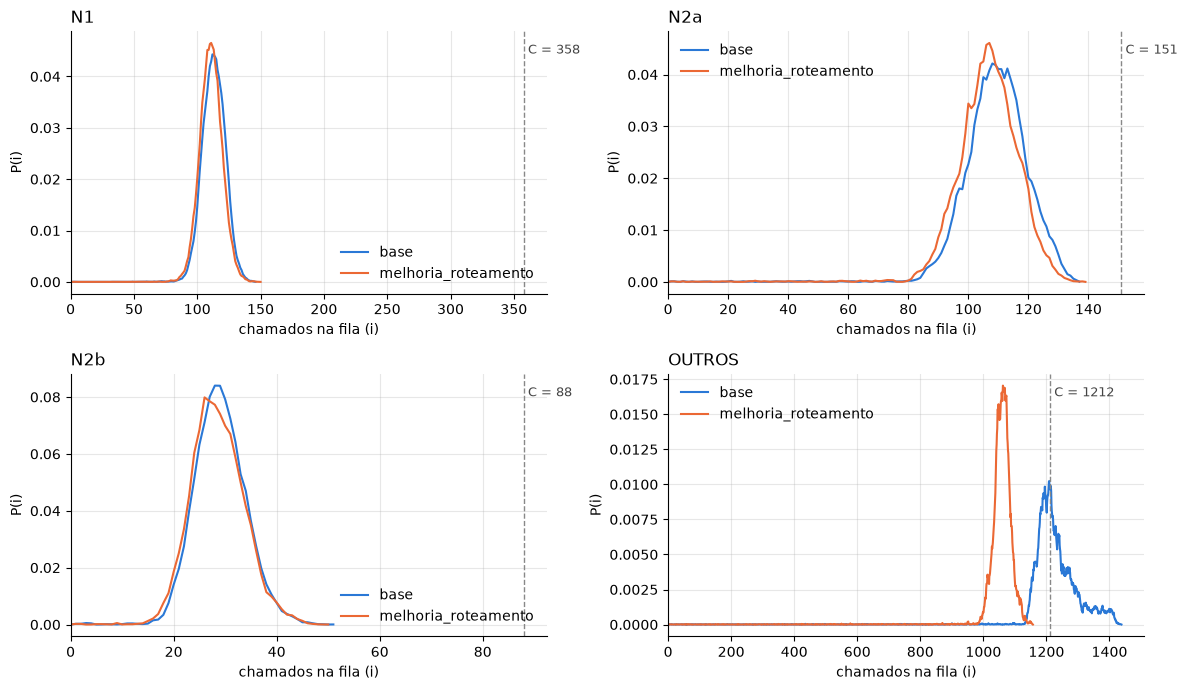

servidores  P(0)  moda  N (média) faixa de 90%  \
fila   modelo                                                                
N1     base                        358   0.0   112    113.049     99 a 127   
       melhoria_roteamento         358   0.0   111    110.851     97 a 125   
N2a    base                        151   0.0   108    109.358     94 a 125   
       melhoria_roteamento         151   0.0   107    106.598     91 a 122   
N2b    base                         88   0.0    28     29.058      21 a 37   
       melhoria_roteamento          88   0.0    26     28.570      21 a 37   
OUTROS base                       1212   0.0  1209   1225.595  1156 a 1366   
       melhoria_roteamento        1212   0.0  1062   1054.066  1014 a 1102   

                            maior estado  P(i >= C)  P(i > C)  
fila   modelo                                                  
N1     base                          146       0.00      0.00  
       melhoria_roteamento           150       0.00      0.00  
N2a    base                          137       0.00      0.00  
       melhoria_roteamento           139       0.00      0.00  
N2b    base                           51       0.00      0.00  
       melhoria_roteamento            50       0.00      0.00  
OUTROS base                         1438       0.55      0.54  
       melhoria_roteamento          1157       0.00      0.00

In [17]:
distribuicao("base", "melhoria_roteamento")

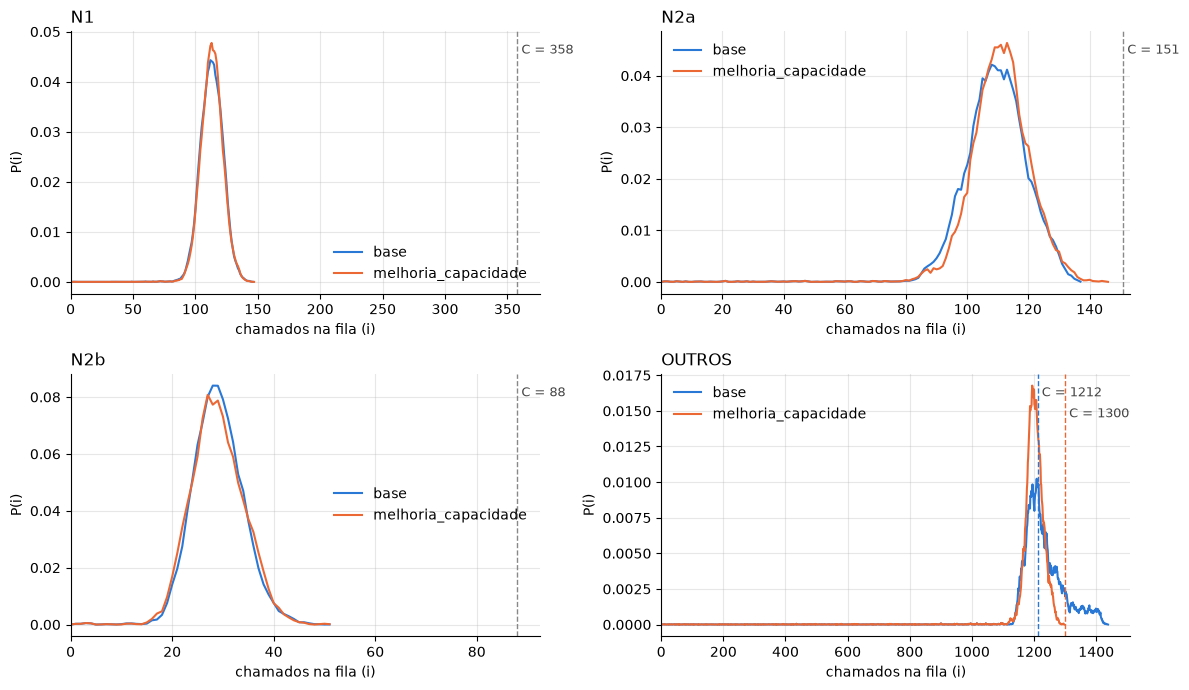

servidores  P(0)  moda  N (média) faixa de 90%  \
fila   modelo                                                                
N1     base                        358   0.0   112    113.049     99 a 127   
       melhoria_capacidade         358   0.0   113    113.188     99 a 127   
N2a    base                        151   0.0   108    109.358     94 a 125   
       melhoria_capacidade         151   0.0   113    110.729     96 a 126   
N2b    base                         88   0.0    28     29.058      21 a 37   
       melhoria_capacidade          88   0.0    27     28.957      21 a 38   
OUTROS base                       1212   0.0  1209   1225.595  1156 a 1366   
       melhoria_capacidade        1300   0.0  1194   1195.508  1159 a 1248   

                            maior estado  P(i >= C)  P(i > C)  
fila   modelo                                                  
N1     base                          146       0.00      0.00  
       melhoria_capacidade           147       0.00      0.00  
N2a    base                          137       0.00      0.00  
       melhoria_capacidade           146       0.00      0.00  
N2b    base                           51       0.00      0.00  
       melhoria_capacidade            51       0.00      0.00  
OUTROS base                         1438       0.55      0.54  
       melhoria_capacidade          1297       0.00      0.00

In [18]:
distribuicao("base", "melhoria_capacidade")

**Conclusão**

- **Cada alteração sozinha elimina a espera em OUTROS:** nas duas, P(todos ocupados) e a espera vão a 0. Mas o efeito é bem diferente.
- **Roteamento (triagem no N1): resolve a causa.** A carga em OUTROS diminui, e a distribuição vai para a esquerda, com no máximo 1157 chamados. Mesmo no pior momento sobram 55 dos 1212 servidores originais. O tempo por chamado na rede cai de 2239 para 1971 min (−12%), porque parte dos chamados deixa de passar por OUTROS, onde cada visita leva cerca de 3090 min.
- **Capacidade (+88 servidores): só abre espaço.** A carga continua a mesma e a distribuição quase não sai do lugar (90% do tempo entre 1159 e 1248 chamados). O maior estado foi 1297, a só 3 servidores do novo limite de 1300, então a espera some por muito pouco: qualquer aumento de demanda volta a formar fila. O tempo por chamado cai só de 2239 para 2196 min (−2%), basicamente a espera que existia em OUTROS.
- **As duas juntas dão o mesmo resultado que só o roteamento:** N da rede e tempo por chamado são idênticos (1971 min), e as distribuições também. Sem fila nos dois cenários, a simulação percorre exatamente os mesmos estados. Com o roteamento, OUTROS nunca usa mais que 1157 servidores, então os 88 extras ficam ociosos: o único efeito é baixar U de 0,870 para 0,811.

Seguindo a reflexão do M9 ("vale a pena contratar mais um médico?"): a capacidade extra não traz ganho quando a triagem é feita e, sozinha, traz um ganho pequeno e frágil. A melhoria que vale a pena é a de roteamento. Essa conclusão depende de duas hipóteses do modelo: o N1 resolve os chamados que deixam de subir sem aumentar o seu tempo de atendimento, e o novo valor de 0,10 é uma estimativa, não um dado medido.